In [4]:
from langchain_groq import ChatGroq

from langgraph.graph import StateGraph,START, END
from typing import TypedDict,Literal,Annotated
from langchain_core.messages import SystemMessage, HumanMessage
import operator
from dotenv import load_dotenv

In [5]:
load_dotenv()  # Load environment variables from .env file

True

In [7]:
import os
Groq_KEY=os.getenv("Groq_KEY") 

In [46]:
from langchain_groq import ChatGroq

# Recommended: switch to the stronger 120B version
MODEL ="openai/gpt-oss-20b"       # ← change this
# MODEL = "qwen/qwen3.8-27b"           # ← or try this one

generate_llm = ChatGroq(
    model=MODEL,
    temperature=0,
    api_key=Groq_KEY
)

evaluate_llm = ChatGroq(
    model=MODEL,
    temperature=0,
    api_key=Groq_KEY
)

optimization_llm = ChatGroq(
    model=MODEL,
    temperature=0,
    api_key=Groq_KEY
)

In [55]:
from pydantic import BaseModel, Field

class postEvaluation(BaseModel):
    evaluate:Literal["approved","need_improvement"]=Field(...,description="The evaluation result of the generated content. It can be either 'approved' or 'need_improvement'.")
    feedback:str=Field(...,description="Feedback provided for the generated content. This field is required if the evaluation result is 'need_improvement'.")


In [53]:
structure_evaluate_llm=evaluate_llm.with_structured_output(postEvaluation)

In [52]:
#wrinting a random post about agentic ai to test the iteration workflow
post="""Agentic AI is revolutionizing the way we interact with technology. With its ability to autonomously perform tasks and make decisions, 
it's opening up new possibilities in various fields.
 some of the key benefits of agentic AI include increased efficiency, improved decision-making, and enhanced user experiences.
However, it's important to consider the ethical implications and ensure that these systems are designed responsibly.
As we continue to develop and integrate agentic AI into our daily lives, we must prioritize transparency, accountability, and fairness to ensure that these technologies benefit society as a whole.
In conclusion, agentic AI has the potential to transform industries and improve our lives, but it must be developed and deployed with careful consideration of its impact on individuals and communities."""

In [57]:
result=structure_evaluate_llm.invoke(post)

In [56]:
result

postEvaluation(evaluate='approved', feedback='')

In [58]:
#now lets define the state

class poststate(TypedDict):
    topic:str
    post:str    
    evaluation:Literal["approved","need_improvement"]
    feedback:str
    iteration:int
    max_iterations:int
    
    
    post_history:Annotated[list[str],operator.add]
    feedback_history:Annotated[list[str],operator.add]

In [59]:
def generate_post(state:poststate):
    message =[
        
        SystemMessage(content="You are a helpful assistant that generates social media posts based on the given topic."),
        HumanMessage(content=f"""Generate a social media post about the topic: {state['topic']}. The post should be engaging and informative.moreover, the post should be concise and should not exceed 280 characters. Please provide the post in plain text format without any additional commentary or explanation.
                     when generating the post, please ensure that it is relevant to the topic and captures the essence of the subject matter.
                     make sure to use clear and concise language that is easy for the audience to understand. Avoid using jargon or technical terms that may confuse the reader.
                     lastly, please ensure that the post is original and does not contain any plagiarized content.
                     """)
    ]
    #send generated message to llm
    response = generate_llm.invoke(message).content
    #return the generated post and add it to the post history
    return {"post": response,'post_history':[response]}


In [60]:
def evaluate_post(state:poststate):
    #evaluate the post using the evaluate llm
    message =[
        SystemMessage(content="You are a helpful assistant that evaluates social media posts based on the given topic."),
        HumanMessage(content=f"""Evaluate the following social media post about the topic: {state['topic']}. The post is: {state['post']}. 
        Please provide your evaluation in the following format:
        1. If the post is relevant to the topic and captures the essence of the subject matter, please respond with 'approved'.
        2. If the post is not relevant to the topic or does not capture the essence of the subject matter, please respond with 'need_improvement' and provide feedback on how to improve it.
        """)
    ]
    #send generated message to llm
    response = structure_evaluate_llm.invoke(message)
    #return the evaluation result and feedback and add it to the feedback history
    return {"evaluation": response.evaluate, "feedback": response.feedback,'feedback_history':[response.feedback]}

In [61]:
def optimize_post(state:poststate):
    #optimize the post using the optimization llm
    message =[
        SystemMessage(content="You are a helpful assistant that optimizes social media posts based on the given topic and feedback."),
        HumanMessage(content=f"""Optimize the following social media post about the topic: {state['topic']}. The post is: {state['post']}. 
        The feedback provided is: {state['feedback']}. Please provide an optimized version of the post that addresses the feedback and improves its relevance to the topic and captures the essence of the subject matter.
        """)
    ]
    #send generated message to llm
    response = optimization_llm.invoke(message).content
    iteration = state['iteration'] + 1
    #return the optimized post and add it to the post history
    return {"post": response,'post_history':[response],'iteration': iteration}

In [63]:
def route_evaluation(state:poststate):
    if state['evaluation'] == "approved" or state['iteration'] >= state['max_iterations']:
        return 'approved'
    else:
        return 'need_improvement'
        

In [76]:
graph=StateGraph(poststate)

#add nodes to the graph
graph.add_node('generate',generate_post)
graph.add_node('evaluate',evaluate_post)
graph.add_node('optimize',optimize_post)

#add edges to the graph
graph.add_edge(START,'generate')
graph.add_edge('generate','evaluate')
graph.add_conditional_edges('evaluate',route_evaluation,{'approved':END,'need_improvement':'optimize'})
graph.add_edge('optimize','evaluate')

In [77]:
workflow=graph.compile()

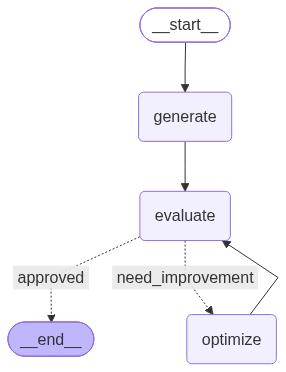

In [78]:
workflow

In [79]:
intial_state={
    "topic":"Agentic AI",
    "iteration":1,
    "max_iterations":3,
}

In [86]:
result=workflow.invoke(intial_state)
result

BadRequestError: Error code: 400 - {'error': {'message': "Tool call validation failed: tool call validation failed: parameters for tool postEvaluation did not match schema: errors: [missing properties: 'feedback']", 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '{"name": "postEvaluation", "arguments": {"evaluate":"approved"}}'}}